In [14]:
# !pip install smt
# !pip install gpytorch
# !pip install pyDOE

In [16]:
# Support for math
import numpy as np
import math

# Plotting tools
from matplotlib import pyplot as plt
import matplotlib

import warnings
warnings.filterwarnings('ignore')

# GPy: Gaussian processes library
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF

# File tools
# from google.colab import drive
# drive.mount('/content/drive')

import pandas as pd

#Latin Hypercube sampling of the input volumes
from smt.sampling_methods import LHS

from scipy.signal import find_peaks

In [17]:
# Path
xls = pd.read_excel("/Users/clarat/Documents/Sun Lab/Mara_colors/mara_color_data/02_23_Random_Color_Increment.xlsx",sheet_name=['End point','RGB'])

df = xls.get('End point')
df_RGB = xls.get('RGB')

df.head()

,Well\nRow,Well\nCol,Content,Concentration,Raw Data (Abs Spectrum),Raw Data (Abs Spectrum).1,Raw Data (Abs Spectrum).2,Raw Data (Abs Spectrum).3,Raw Data (Abs Spectrum).4,Raw Data (Abs Spectrum).5,...,Raw Data (Abs Spectrum).141,Raw Data (Abs Spectrum).142,Raw Data (Abs Spectrum).143,Raw Data (Abs Spectrum).144,Raw Data (Abs Spectrum).145,Raw Data (Abs Spectrum).146,Raw Data (Abs Spectrum).147,Raw Data (Abs Spectrum).148,Raw Data (Abs Spectrum).149,Raw Data (Abs Spectrum).150
0,NaN,NaN,Wavelength [nm],NaN,400.000,402.000,404.000,406.000,408.000,410.000,...,682.000,684.000,686.000,688.000,690.000,692.000,694.000,696.000,698.000,700.000
1,D,1.0,Sample X37,74626.252,1.363,1.391,1.409,1.438,1.459,1.474,...,0.043,0.042,0.040,0.038,0.035,0.034,0.033,0.031,0.030,0.030
2,D,2.0,Sample X38,25529.573,0.627,0.648,0.663,0.677,0.689,0.694,...,0.066,0.061,0.056,0.051,0.047,0.043,0.041,0.037,0.036,0.035
3,D,3.0,Sample X39,42472.278,0.997,1.023,1.044,1.065,1.080,1.093,...,0.067,0.061,0.057,0.053,0.050,0.047,0.044,0.041,0.040,0.038
4,D,4.0,Sample X40,32500.649,1.461,1.497,1.528,1.560,1.574,1.584,...,0.277,0.267,0.260,0.253,0.247,0.243,0.239,0.236,0.234,0.231


In [18]:
from pyDOE import lhs
def latin_hypercube_sum_constraint(n_samples, n_variables, sum_constraint):
    # Step 1: Generate Latin Hypercube Samples
    np.random.seed(2)
    lhs_samples = lhs(n_variables, samples=n_samples, criterion='maximin')
    #sampling = LHS(xlimits=xlimits,random_state = np.random.RandomState(0))

    # Step 2: Transform samples to satisfy the sum constraint
    for i in range(n_samples):
        current_sum = np.sum(lhs_samples[i, :])
        lhs_samples[i, :] *= sum_constraint / current_sum

    return lhs_samples

sampled_colors = latin_hypercube_sum_constraint(12, 3, 300)//1
sampled_colors.transpose()

array([[ 82., 165., 105.,  26., 109.,  84.,  32., 214., 114., 139., 214.,
         15.],
       [ 39.,  76.,  78., 122., 128., 124., 153.,  37., 125., 100.,  39.,
         69.],
       [177.,  57., 116., 150.,  62.,  91., 114.,  47.,  59.,  59.,  46.,
        214.]])

In [19]:
#Latin Hypercube sampling of the input volumes
from smt.sampling_methods import LHS

#max volume is 300 for one well
xlimits = np.array([[0.0, 300.0], [0.0, 300.0],[0.0,300.0]])
sampling = LHS(xlimits=xlimits,random_state = np.random.RandomState(0))

num = 12
x = sampling(num)//1


In [20]:
#input data:
# vol_red  = [100,50,200,50,150,0,150,25,75,25,75,100]
# vol_blue = [100,200,50,50,150,150,0,75,25,175,200,70]
# vol_yelo = [100,50,50,200,0,150,150,200,200,100,25,130]

vol_red  = sampled_colors[:,0]
vol_blue = sampled_colors[:,1]
vol_yelo = sampled_colors[:,2]
vol_red

array([ 82., 165., 105.,  26., 109.,  84.,  32., 214., 114., 139., 214.,
        15.])

In [21]:
#Example spectra
xvals = df.iloc[0, 4:]
yvals = df.iloc[1,4:]

data1 = [df.iloc[0, 4:],df.iloc[1,4:]]
data2 = [df.iloc[0, 4:],df.iloc[2,4:]]

In [22]:
colors = [(0.137,0.235,0.149),(0.000,0.282,0.349),(0.365,0.208,0.200),(0.361,0.451,0.004),(0.090,0.063,0.573),(0.000,0.478,0.082),(0.820,0.392,0.027),(0.153,0.443,0.000),
          (0.455,0.349,0.000),(0.000,0.345,0.196),(0.004,0.180,0.396),(0.224,0.231,0.075)]
data_color = [1,2,3,4,5,6,7,8,9,10,11,12]

colors_R = df_RGB.loc[:,'R/255']
colors_G = df_RGB.loc[:,'G/255']
colors_B = df_RGB.loc[:,'B/255']

colors_RGB = list(zip(colors_R,colors_G,colors_B))
colors_RGB

[(0.3254901961, 0.2862745098, 0.07843137255),
 (0.1254901961, 0.1137254902, 0.1960784314),
 (0.137254902, 0.1803921569, 0.1490196078),
 (0.0, 0.3529411765, 0.2117647059),
 (0.003921568627, 0.1176470588, 0.2745098039),
 (0.0, 0.1450980392, 0.2156862745),
 (0.007843137255, 0.2941176471, 0.2666666667),
 (0.2470588235, 0.1098039216, 0.1882352941),
 (0.01176470588, 0.1215686275, 0.3058823529),
 (0.05882352941, 0.09411764706, 0.2549019608),
 (0.2117647059, 0.1176470588, 0.1725490196),
 (0.0, 0.5882352941, 0.07450980392)]

#Functions

In [66]:
from mpl_toolkits.axisartist.axislines import Axes

def plot_spec(id,color):
  data = [df.iloc[0, 4:],df.iloc[id,4:]]

  peaks, _ = find_peaks(data[1], prominence=0.1)
  fig = plt.figure(figsize=(3, 3))

  ax = fig(axes_class=Axes)
  ax.plot(data[0],data[1], color = color)
  ax.axis["right"].set_visible(False)
  ax.axis["top"].set_visible(False)
  ax.vlines(data[0].values[peaks], 0, np.max(data[1]), linestyle='--', color='tab:grey')#'dodgerblue'

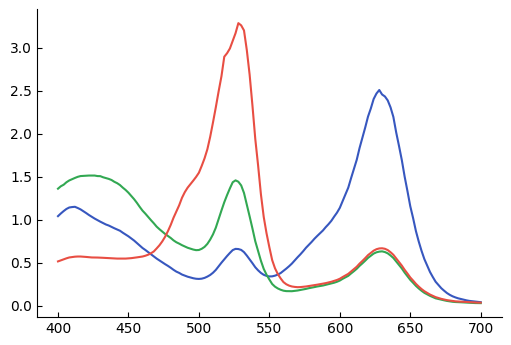

In [63]:
fig = plt.figure(figsize=(6, 4))
data = [df.iloc[0, 4:],df.iloc[1,4:]]
ax = fig.add_subplot(axes_class=Axes)
ax.plot(data[0],df.iloc[7,4:], color = (55/255, 87/255, 191/255))
ax.plot(data[0],df.iloc[1,4:], color = (50/255, 168/255, 82/255))
ax.plot(data[0],df.iloc[11,4:], color = (232/255, 78/255, 67/255))
ax.axis["right"].set_visible(False)
ax.axis["top"].set_visible(False)



In [24]:
def selection(color):
  xvals = df.iloc[0, 4:]
  yvals = df.iloc[color,4:]

  xvals = np.array(xvals)
  yvals = np.array(yvals)
  return xvals,yvals

In [25]:
def weight_avg(color):
  data = [df.iloc[0, 4:],df.iloc[color,4:]]

  peaks, _ = find_peaks(data[1], prominence=0.1)

  wavelength = data[0].values[peaks]
  magnitude = data[1].values[peaks]
  magwave = 0.0
  for i in range(wavelength.shape[0]):
    magwave += wavelength[i]*(magnitude[i])

  return magwave/sum(magnitude)


In [26]:
def largest_peak(color):
  data = [df.iloc[0, 4:],df.iloc[color,4:]]
  peaks, _ = find_peaks(data[1], prominence=0.01)
  # print(peaks)
  # print(np.argmax((data[1].values[peaks])))
  # print(data[1].values[peaks])
  # print(data[0].values[peaks])
  id_max_mag = np.argmax((data[1].values[peaks]))
  id_max_peak = peaks[id_max_mag]

  wavelength = data[0][id_max_peak]
  return wavelength

In [27]:
from sklearn import preprocessing
def plot_normalized(ID,color):
    data = [df.iloc[0, 4:],df.iloc[ID,4:]]

    peaks, _ = find_peaks(data[1], prominence=0.01)

    #Step1 Normalize the spectra
    normalized_data = preprocessing.normalize(data)
    plt.plot(data[0],normalized_data[1],color = color)
    plt.vlines(data[0].values[peaks], 0, np.max(normalized_data[1]), linestyle='--', color='tab:grey')#'dodgerblue'

In [28]:
def interval_selection(id,min,max):
  min = np.where(df==min)[1][0]
  max = np.where(df==max)[1][0]+1

  new_x= df.iloc[0, min:max]
  new_y = df.iloc[id,min:max]
  return [new_x,new_y]

#interval area
def area_color(id,min,max):
  x,y = interval_selection(id,min,max)
  area = np.trapz(y, x)
  return area


In [29]:
def spectral_transfrom(ID,color):
    data = [df.iloc[0, 4:],df.iloc[ID,4:]]
    #Step1 Normalize the spectra
    normalized_data = preprocessing.normalize(data)

    #Step 2, are there three distinct peaks?
    peaks, _ = find_peaks(normalized_data[1], prominence=0.01)

    #if

    #Step 3 find the area of the peaks
    low_spec = area_color(ID,400,450)
    mid_spec = area_color(ID,500,550)
    low_spec = area_color(ID,600,650)


    #Plot the results
    plt.plot(data[0],normalized_data[1],color = color)
    plt.vlines(data[0].values[peaks], 0, np.max(normalized_data[1]), linestyle='--', color='tab:grey')#'dodgerblue'

#Spectral Transfroms

<Figure size 600x400 with 0 Axes>

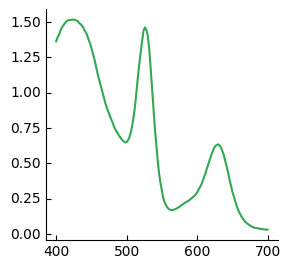

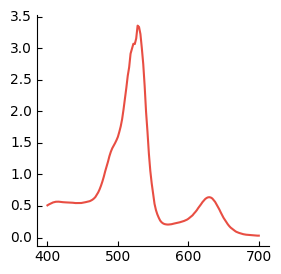

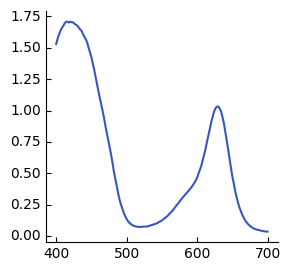

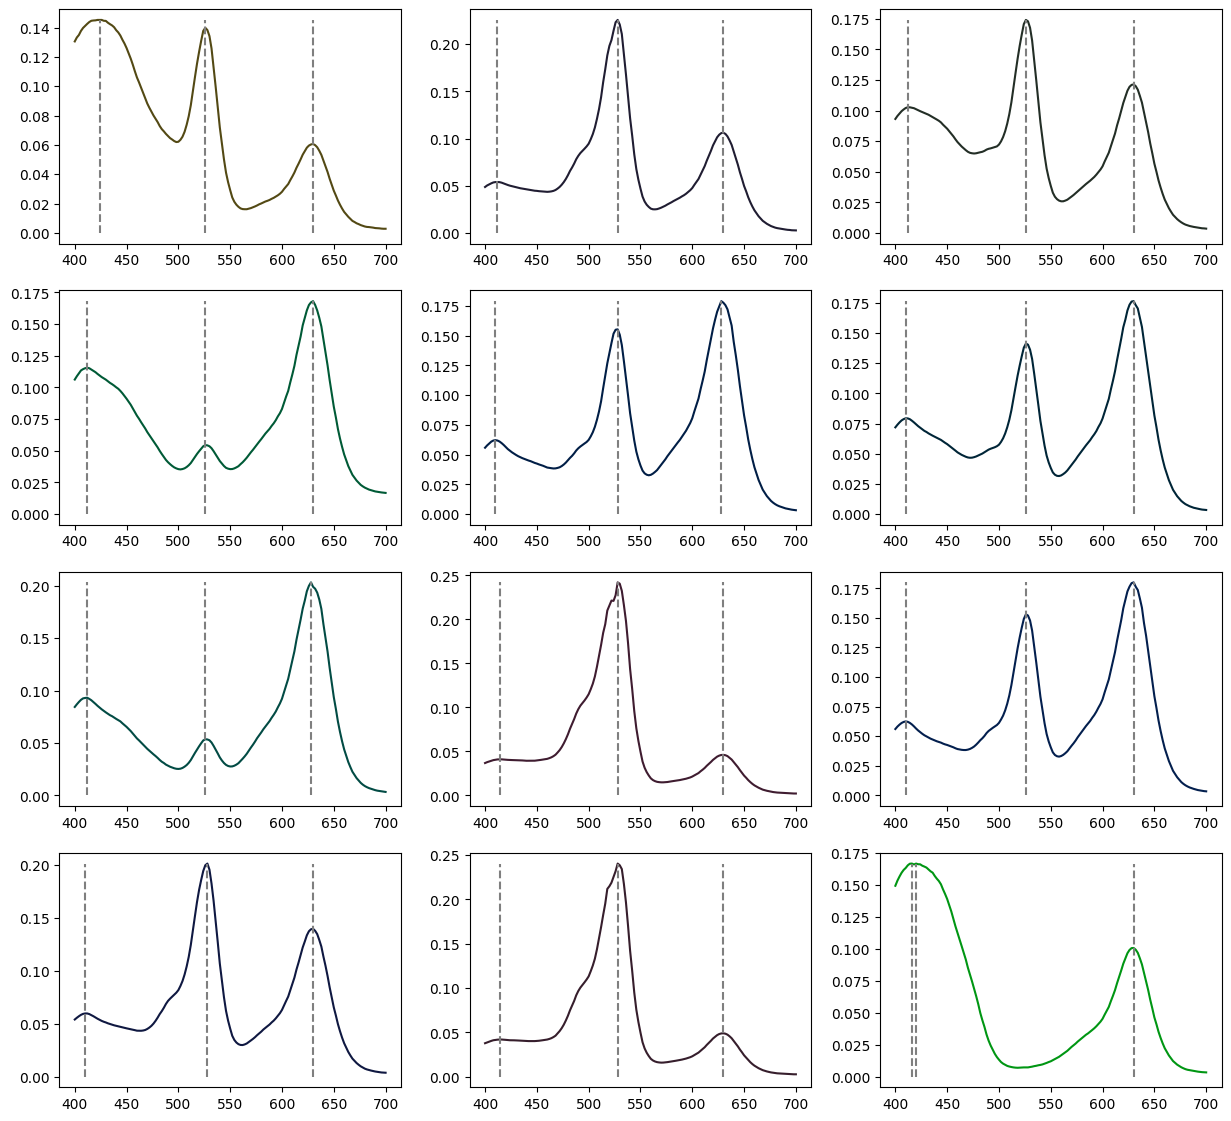

In [96]:
#plot the normalized spectra
fig = plt.figure(figsize=(15,14))
#Spectra vs Weights
for i in range(len(data_color)):
  plt.subplot(4,3,i+1)
  plot_normalized(i+1,colors_RGB[i])



#Weighted Sum

In [20]:
## Weighted sum method
from scipy.signal import find_peaks
def dot_val(id):
  data = [df.iloc[0, 4:],df.iloc[id,4:]]
  # Find peaks
  peaks, _ = find_peaks(data[1], prominence=0.1)

  #plt.plot(data[0],data[1])
  #plt.vlines(data[0].values[peaks], 0, np.max(data[1]), linestyle='--', color='dodgerblue')

  #weights = np.array([0.5, 1.0, 0.8])  # Adjust weights based on importance
  #unique_value = np.dot(weights, yvals)

  weights = np.zeros(peaks.shape)
  peakvals = np.zeros(peaks.shape)
  for i in range(peaks.shape[0]):
    weights[i] = (data[1][peaks[i]]/data[1][peaks[0]])
    peakvals[i] = (data[1][peaks[i]])

  unique_val = np.dot(weights,peakvals)
  return unique_val

In [21]:
dot_color = np.zeros(len(data_color))
for i in range(len(data_color)):
  dot_color[i] = dot_val(data_color[i])/1.0


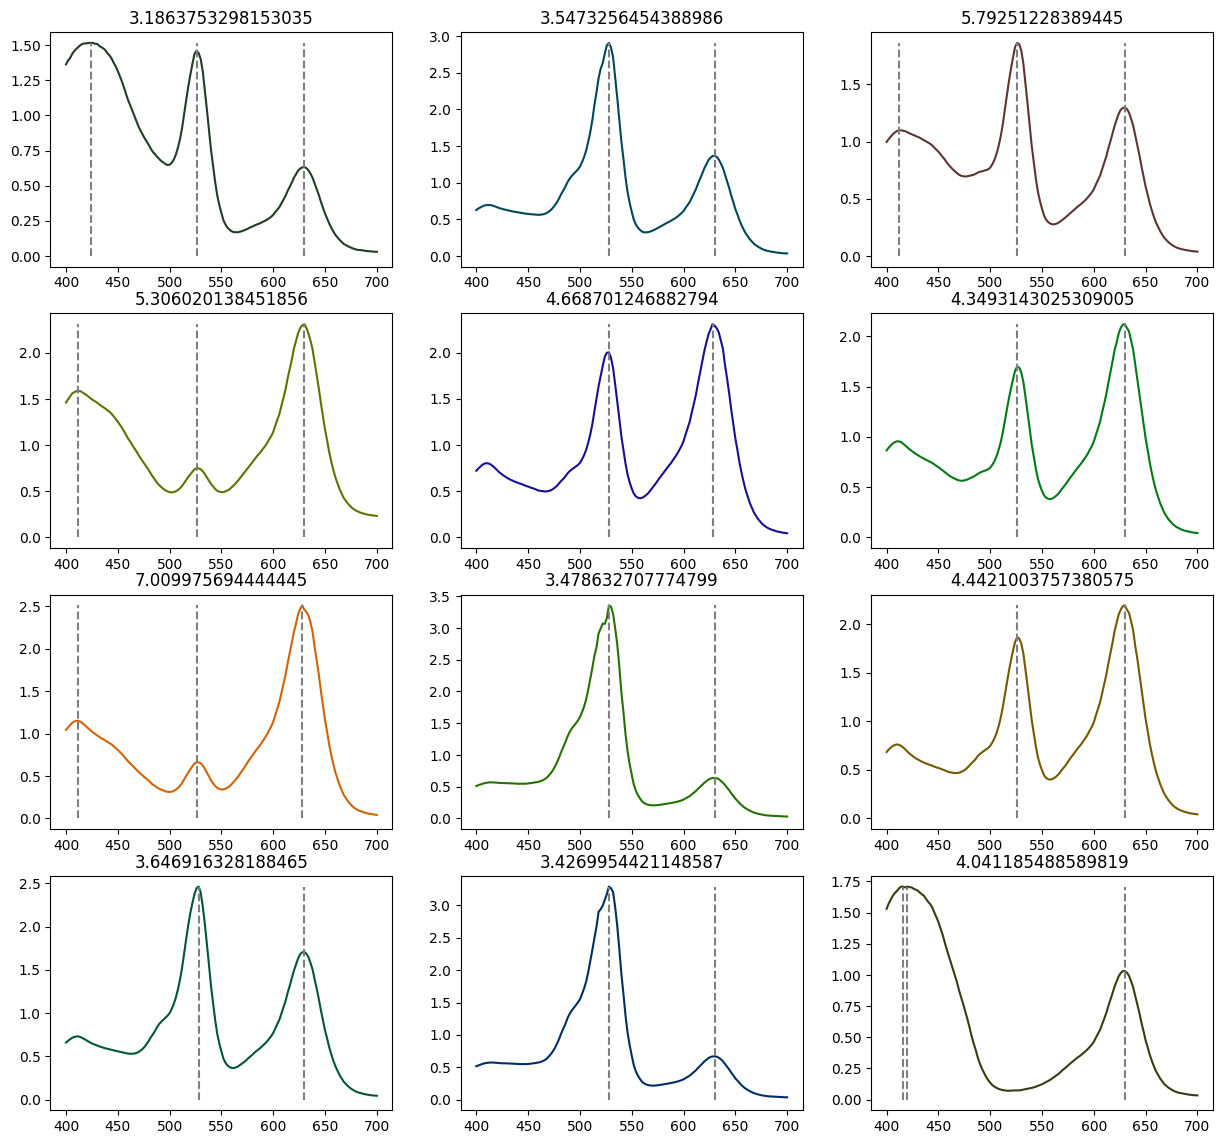

In [22]:
fig = plt.figure(figsize=(15,14))
#Spectra vs Weights
for i in range(len(data_color)):
  plt.subplot(4,3,i+1)
  plot_spec(i+1,colors[i])
  plt.title('%s' %dot_color[i])

#Principal component analysis method

In [12]:
#Principal component analysis
from sklearn.decomposition import PCA

# Assuming 'absorbance_data' is your absorption spectrum (single sample)
n_components = 1  # Number of components to retain

# Apply PCA
pca = PCA(n_components = n_components)
val1 = pca.fit_transform(data1)
val2 = pca.fit_transform(data2)

val1,val2


(array([[ 3417.70920848],
        [-3417.70920848]]),
 array([[ 3416.56555779],
        [-3416.56555779]]))

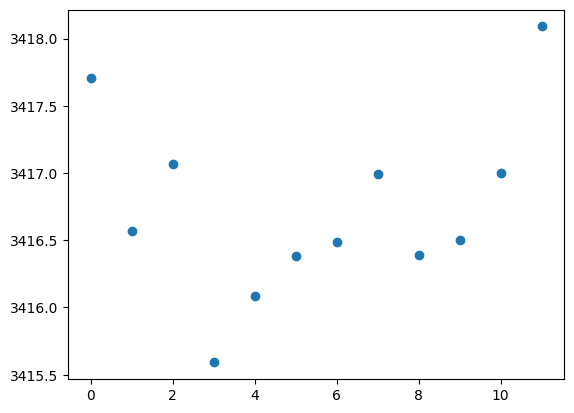

In [15]:
pca_color = np.zeros(len(data_color))
for i in range(len(data_color)):
  data = [df.iloc[0, 4:],df.iloc[i+1,4:]]
  #pca is 2,1
  pca_color[i] = abs(pca.fit_transform(data)[0])

pca_color

plt.plot(pca_color,'o')

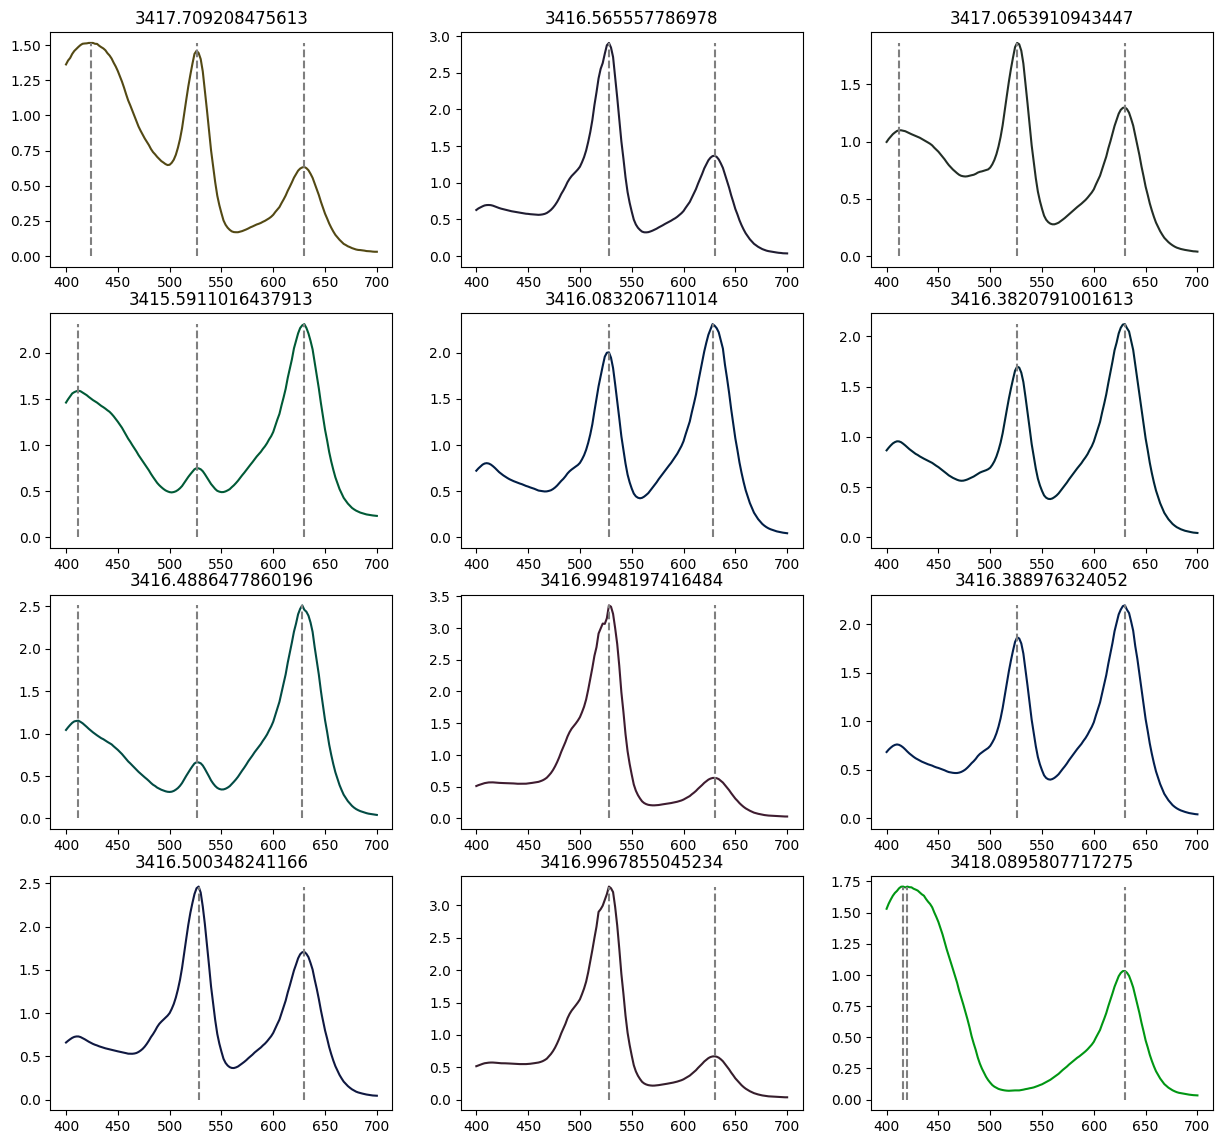

In [19]:
fig = plt.figure(figsize=(15,14))
#Spectra vs Weights
for i in range(len(data_color)):
  plt.subplot(4,3,i+1)
  plot_spec(i+1,colors_RGB[i])
  plt.title('%s' %pca_color[i])
  #plt.xlabel('%s' %weight_color[i])

#OTHER

In [23]:
weight_color = np.zeros(len(data_color))
for i in range(len(data_color)):
  weight_color[i] = weight_avg(data_color[i])//1

weight_color


array([501., 560., 528., 538., 581., 583., 554., 544., 582., 569., 545.,
       467.])

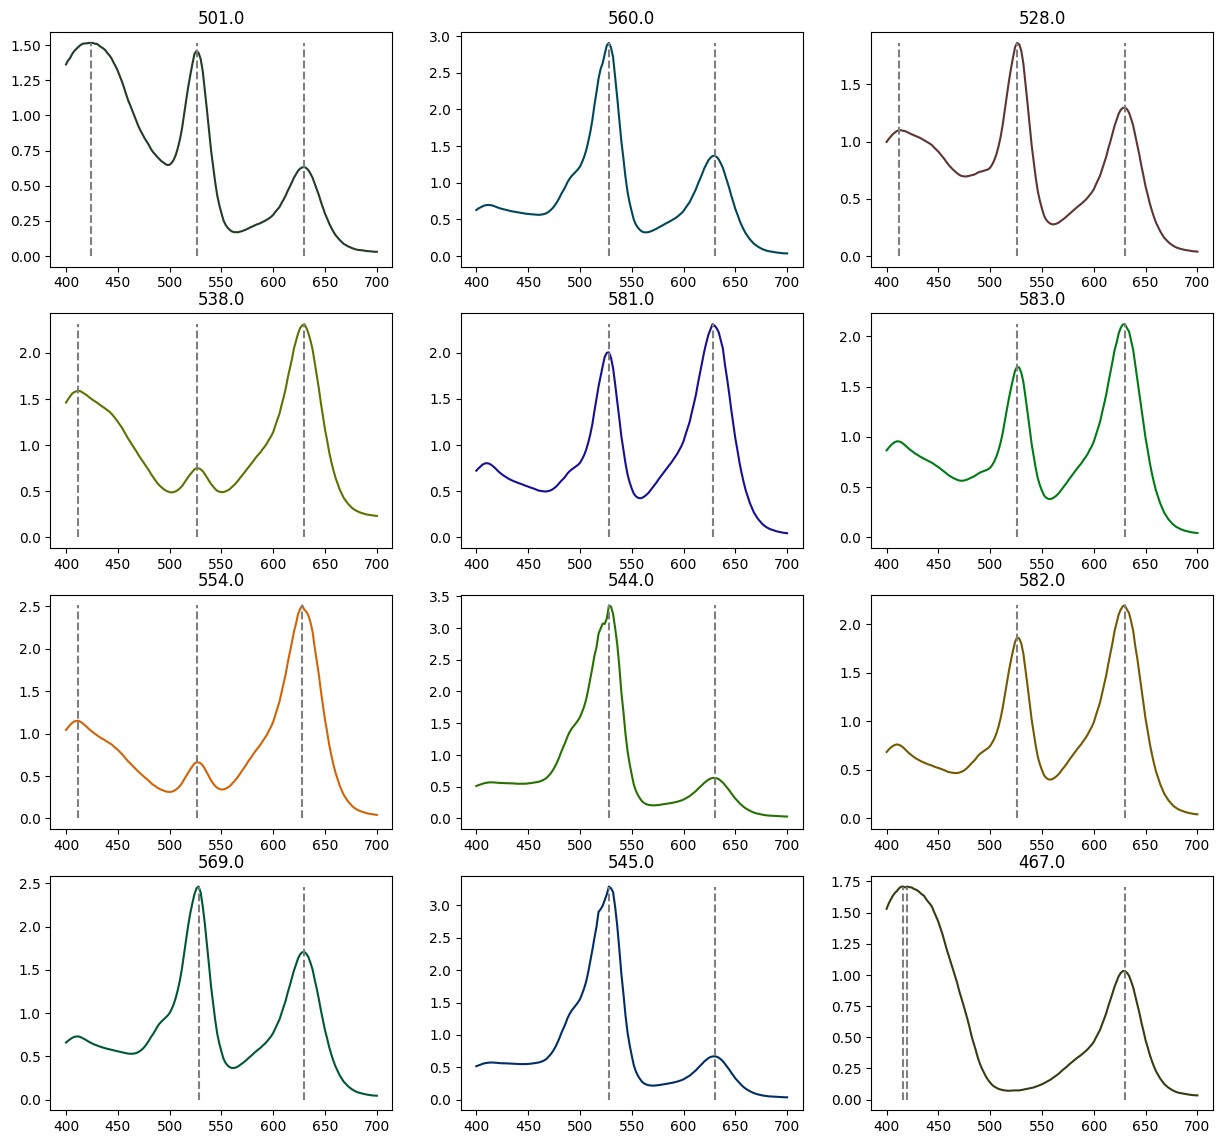

In [24]:
fig = plt.figure(figsize=(15,14))
#Spectra vs Weights
for i in range(len(data_color)):
  plt.subplot(4,3,i+1)
  plot_spec(i+1,colors[i])
  plt.title('%s' %weight_color[i])
  #plt.xlabel('%s' %weight_color[i])

In [25]:
peak_color = np.zeros(len(data_color))
for i in range(len(data_color)):
  peak_color[i] = largest_peak(data_color[i])

peak_color

array([424., 528., 526., 630., 628., 630., 628., 528., 630., 528., 528.,
       416.])

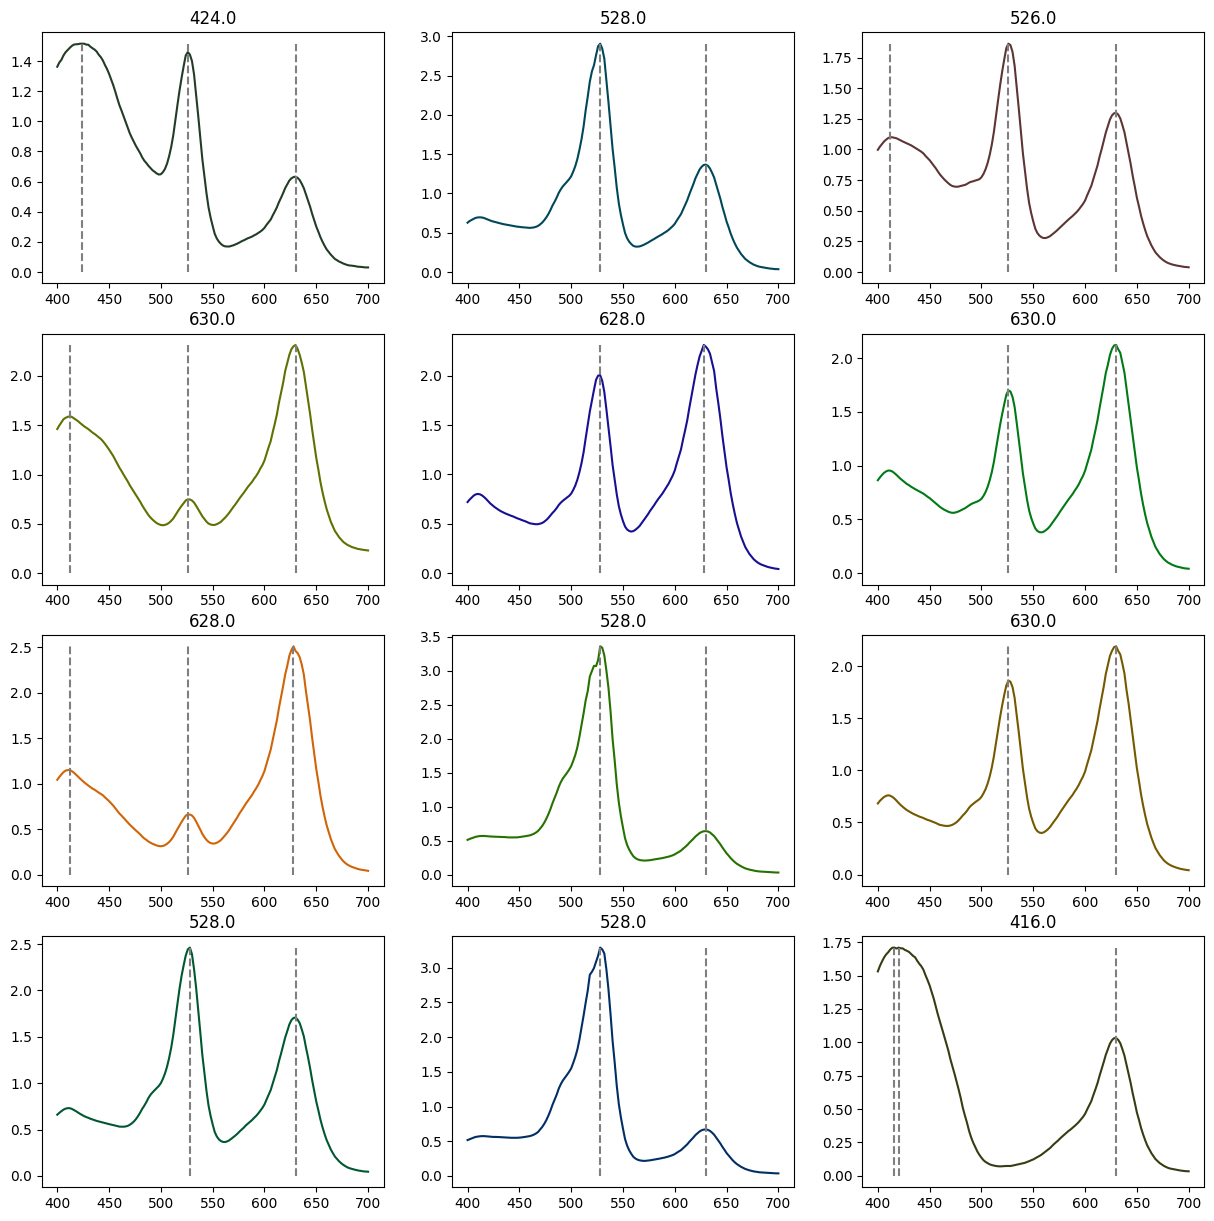

In [26]:
fig = plt.figure(figsize=(15,15))
#Spectra vs Weights
for i in range(len(data_color)):
  plt.subplot(4,3,i+1)
  plot_spec(i+1,colors[i])
  plt.title('%s' %peak_color[i])

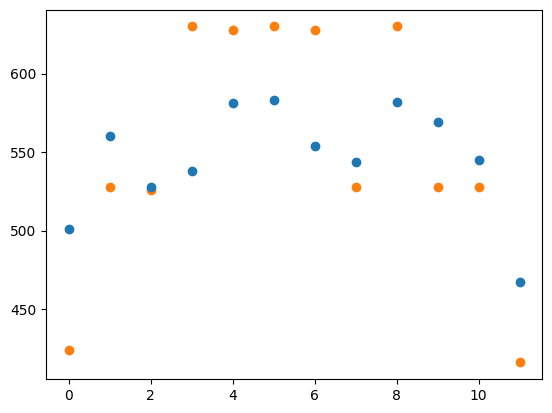

In [37]:
#plot of peak colors for each ID
plt.plot(peak_color,'bo',color = "tab:orange")
plt.plot(weight_color, 'bo', color = "tab:blue")

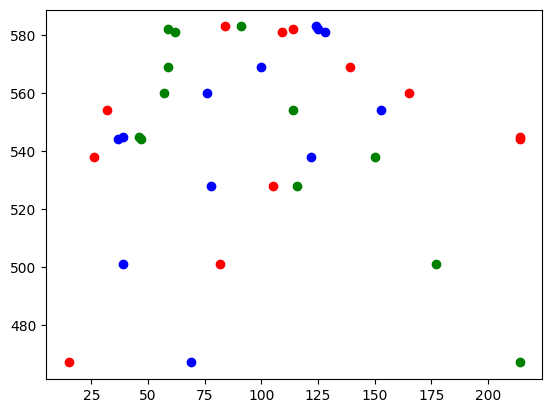

In [29]:
#plot of peak colors
#plt.plot(peak_color,'bo')
plt.plot(vol_red,weight_color,'bo',color = 'red')
plt.plot(vol_blue,weight_color,'bo',color = 'blue')
plt.plot(vol_yelo,weight_color,'bo',color = 'green')

#Gaussian Process

In [60]:
#Sort the data
data = {
  "vol_red": vol_red,
  "vol_blue": vol_blue,
  "vol_yellow": vol_yelo,
  "color": pca_color
}
data = pd.DataFrame(data)

data = np.array(data.sort_values('vol_red'))
data

array([[  15.        ,   69.        ,  214.        , 3418.08958077],
       [  26.        ,  122.        ,  150.        , 3415.59110164],
       [  32.        ,  153.        ,  114.        , 3416.48864779],
       [  82.        ,   39.        ,  177.        , 3417.70920848],
       [  84.        ,  124.        ,   91.        , 3416.3820791 ],
       [ 105.        ,   78.        ,  116.        , 3417.06539109],
       [ 109.        ,  128.        ,   62.        , 3416.08320671],
       [ 114.        ,  125.        ,   59.        , 3416.38897632],
       [ 139.        ,  100.        ,   59.        , 3416.50034824],
       [ 165.        ,   76.        ,   57.        , 3416.56555779],
       [ 214.        ,   37.        ,   47.        , 3416.99481974],
       [ 214.        ,   39.        ,   46.        , 3416.9967855 ]])

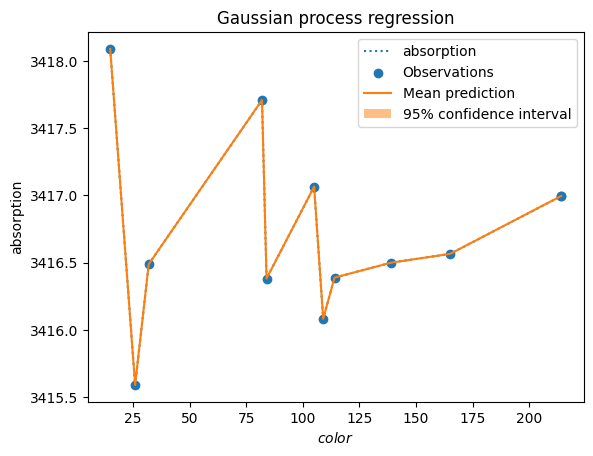

In [61]:
#sklearn gaussian process
X = data[:,0].reshape(-1,1)
X_train = data[:,0].reshape(-1,1)
Y_train = data[:,3].reshape(-1,1)

#Training
kernel = 1 * RBF(length_scale=1.0, length_scale_bounds=(1e-2, 1e2))
gaussian_process = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=3)
gaussian_process.fit(X_train, Y_train)
gaussian_process.kernel_

mean_prediction, std_prediction = gaussian_process.predict(X, return_std=True)

plt.plot(X, Y_train, label=r"absorption", linestyle="dotted")
plt.scatter(X_train, Y_train, label="Observations")
plt.plot(X, mean_prediction, label="Mean prediction")
plt.fill_between(
    X.ravel(),
    mean_prediction - 1.96 * std_prediction,
    mean_prediction + 1.96 * std_prediction,
    alpha=0.5,
    label=r"95% confidence interval",
)
plt.legend()
plt.xlabel("$color$")
plt.ylabel("absorption")
_ = plt.title("Gaussian process regression")

In [62]:
#Data to use
red = data[:,0].reshape(-1,1)
blue = data[:,1].reshape(-1,1)
yelo = data[:,2].reshape(-1,1)

X = data[:, [0,1,2]]
Y = data[:,3].reshape(-1,1)